# MAKİNE ÖĞRENMESİ PROJESİ (One-Hot Encoding Versiyonu)

**Yöntem:** Bu notebook'ta kategorik değişkenler için Label Encoding yerine **One-Hot Encoding** kullanılmıştır. Veri setinin aşırı büyümesini engellemek için nadir görülen kategoriler gruplandırılmıştır.

---

In [1]:
# Gerekli Kütüphaneler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# ML Kütüphaneleri
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Modeller
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# XAI
import shap

import warnings
warnings.filterwarnings('ignore')

# Veriyi Oku
df = pd.read_csv('cleaned_used_cars.csv')
df = df.dropna(subset=['price']) # Hedef değişkeni boş olanları at
print("Veri Boyutu:", df.shape)

Veri Boyutu: (4009, 12)


## 1. Veri Ön İşleme ve Özellik Mühendisliği

In [2]:
# 1.1. Temel Temizlik
df.replace(['–', '—', 'nan', 'None'], np.nan, inplace=True)

# 1.2. Engine Sütununu Ayrıştırma
def extract_hp(text):
    if pd.isna(text): return np.nan
    match = re.search(r'(\d+\.?\d*)HP', str(text))
    return float(match.group(1)) if match else np.nan

def extract_liters(text):
    if pd.isna(text): return np.nan
    match = re.search(r'(\d+\.?\d*)L', str(text))
    return float(match.group(1)) if match else np.nan

df['horsepower'] = df['engine'].apply(extract_hp)
df['engine_liters'] = df['engine'].apply(extract_liters)
df.drop(columns=['engine'], inplace=True)

# 1.3. Eksik Verileri Doldurma
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    if len(df[col].mode()) > 0:
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna('Unknown')

# 1.4. Outlier Temizliği (IQR)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
df_cleaned = df[(df['price'] >= (Q1 - 1.5 * IQR)) & (df['price'] <= (Q3 + 1.5 * IQR))].copy()

print(f"Temizlenmiş Veri Boyutu: {df_cleaned.shape}")
df_cleaned.to_csv('1_data_cleaned.csv', index=False)

Temizlenmiş Veri Boyutu: (3765, 13)


## 2. One-Hot Encoding Hazırlığı (Kritik Aşama)
One-Hot Encoding, her kategori için yeni bir sütun (0 veya 1) oluşturur. 'Model' sütununda yüzlerce farklı araba modeli olduğu için, bu işlem sütun sayısını aşırı artırabilir (Curse of Dimensionality). Bunu önlemek için az rastlanan modelleri 'Other' olarak gruplayacağız.

In [3]:
# Nadir kategorileri gruplama fonksiyonu
def shorten_categories(df, col, threshold=20):
    # Eğer bir kategori 'threshold' sayısından az geçiyorsa 'Other' yap
    val_counts = df[col].value_counts()
    keep = val_counts[val_counts >= threshold].index
    df[col] = df[col].apply(lambda x: x if x in keep else 'Other')
    return df

# Kategorik sütunları belirle
categorical_features = df_cleaned.select_dtypes(include=['object']).columns

# Gruplamayı uygula (Model ve Brand için önemli)
for col in categorical_features:
    df_cleaned = shorten_categories(df_cleaned, col, threshold=30)

print("Kategorik değişkenler gruplandı. Şimdi One-Hot Encoding uygulanıyor...")

# 2.1. One-Hot Encoding Uygulaması (pd.get_dummies)
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_features, drop_first=True, dtype=int)

print(f"Encoding Sonrası Sütun Sayısı: {df_encoded.shape[1]}")
df_encoded.head()

Kategorik değişkenler gruplandı. Şimdi One-Hot Encoding uygulanıyor...
Encoding Sonrası Sütun Sayısı: 82


,model_year,milage,clean_title,price,accident_binary,horsepower,engine_liters,brand_Audi,brand_BMW,brand_Buick,...,ext_col_Silver,ext_col_White,int_col_Black,int_col_Brown,int_col_Ebony,int_col_Gray,int_col_Jet Black,int_col_Other,int_col_Red,int_col_White
0,2013,51000,1,10300,1,300.0,3.7,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,2021,34742,1,38005,1,310.0,3.8,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,2022,22372,0,54598,0,310.0,3.5,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,2015,88900,1,15500,0,354.0,3.5,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,2021,9835,0,34999,0,310.0,2.0,1,0,0,...,0,0,1,0,0,0,0,0,0,0


## 3. Ölçeklendirme ve PCA (Boyut İndirgeme)
One-Hot Encoding sütun sayısını artırdığı için PCA kullanımı burada daha da önem kazanır.

In [4]:
# X ve y ayırımı
X = df_encoded.drop('price', axis=1)
y = df_encoded['price']

# 3.1. Standardizasyon
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=X.columns).to_csv('2_data_onehot_scaled.csv', index=False)

# 3.2. PCA Uygulaması
# Varyansın %95'ini koru
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

print(f"Orijinal Özellik Sayısı: {X.shape[1]}")
print(f"PCA Sonrası Özellik Sayısı: {X_pca.shape[1]}")

# Sonucu kaydet
pca_cols = [f'PC{i+1}' for i in range(X_pca.shape[1])]
df_pca = pd.DataFrame(X_pca, columns=pca_cols)
df_pca['price'] = y.values
df_pca.to_csv('3_data_onehot_pca.csv', index=False)

Orijinal Özellik Sayısı: 81
PCA Sonrası Özellik Sayısı: 67


## 4. Modelleme ve Eğitim

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "SVR": SVR(C=1000), # SVR için C parametresini biraz artırdık
    "KNN": KNeighborsRegressor()
}

results = {}

print("Eğitim Başladı (One-Hot Veri Seti ile)...")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    results[name] = {"R2": r2, "RMSE": rmse}
    print(f"{name} -> R2: {r2:.4f}, RMSE: {rmse:.0f}")

Eğitim Başladı (One-Hot Veri Seti ile)...
Linear Regression -> R2: 0.6286, RMSE: 12758
Decision Tree -> R2: 0.2987, RMSE: 17533
Random Forest -> R2: 0.6622, RMSE: 12169
SVR -> R2: 0.5160, RMSE: 14565
KNN -> R2: 0.4298, RMSE: 15810


  File "c:\Users\ysfygc\anaconda3\envs\BTK\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\ysfygc\anaconda3\envs\BTK\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\ysfygc\anaconda3\envs\BTK\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\ysfygc\anaconda3\envs\BTK\lib\subprocess.py", line 1456, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


## 5. Sonuçların Karşılaştırılması

,R2,RMSE
Linear Regression,0.628631,12758.427107
Decision Tree,0.298680,17532.845610
Random Forest,0.662158,12168.896193
SVR,0.515987,14565.405707
KNN,0.429760,15809.687066


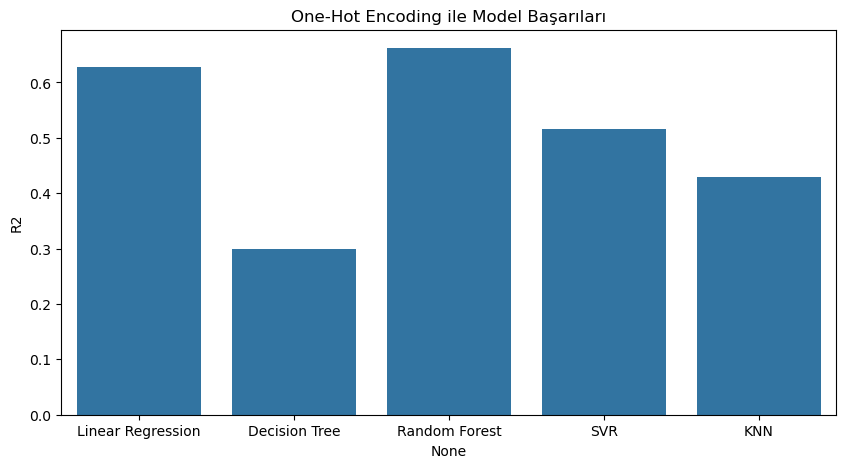

In [6]:
results_df = pd.DataFrame(results).T
display(results_df)

plt.figure(figsize=(10,5))
sns.barplot(x=results_df.index, y=results_df['R2'])
plt.title('One-Hot Encoding ile Model Başarıları')
plt.show()

results_df.to_csv('4_onehot_results.csv')

## 6. Açıklanabilir Yapay Zeka (SHAP)
One-Hot Encoding kullanıldığında SHAP analizi daha detaylı olur. Örneğin 'Marka_BMW' gibi spesifik özelliklerin etkisini görebiliriz.

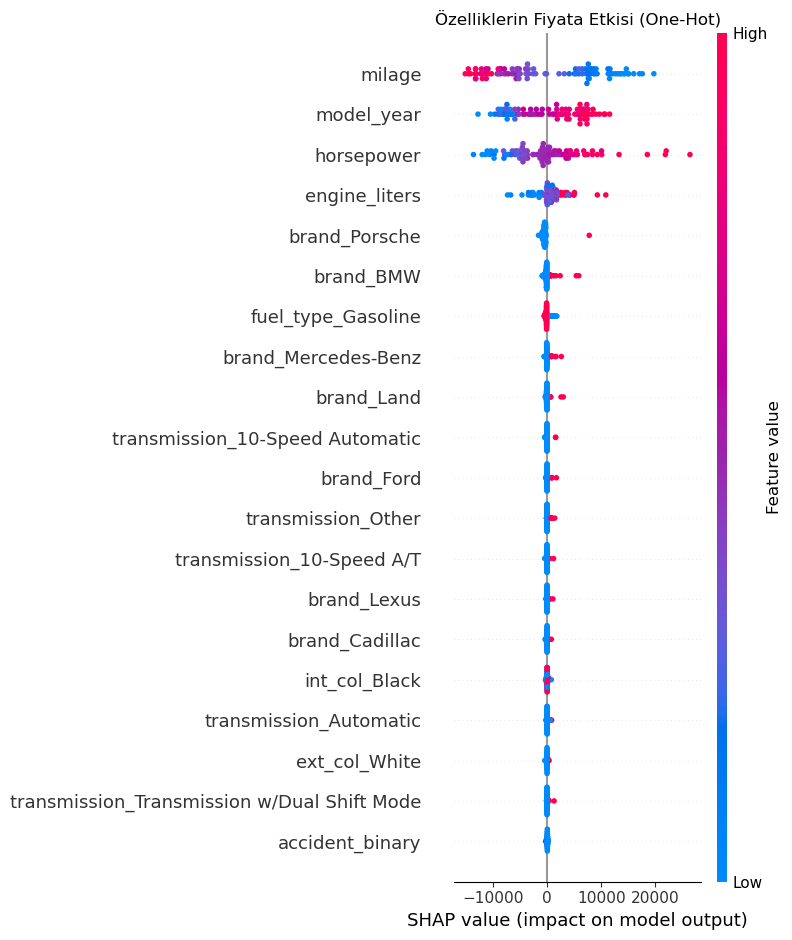

In [7]:
# SHAP için PCA öncesi orijinal (One-Hot yapılmış) veriyi kullanalım ki özellik isimleri görünsün
X_train_orig, X_test_orig, y_train_orig, y_test_orig = train_test_split(X, y, test_size=0.2, random_state=42)

# Hızlı açıklama için küçük bir Random Forest kuralım
rf_exp = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42)
rf_exp.fit(X_train_orig, y_train_orig)

explainer = shap.TreeExplainer(rf_exp)
# Test setinden küçük bir örneklem alalım (Hız için)
shap_values = explainer.shap_values(X_test_orig.iloc[:100])

plt.figure()
shap.summary_plot(shap_values, X_test_orig.iloc[:100], show=False)
plt.title("Özelliklerin Fiyata Etkisi (One-Hot)")
plt.tight_layout()
plt.savefig('5_shap_onehot.png')
plt.show()